In [2]:
!pip uninstall -y opencv-python opencv-python-headless opencv-contrib-python opencv-contrib-python-headless
!pip install opencv-python==4.10.0.84

Found existing installation: opencv-python 5.0.0.93
Uninstalling opencv-python-5.0.0.93:
  Successfully uninstalled opencv-python-5.0.0.93
Found existing installation: opencv-python-headless 5.0.0.93
Uninstalling opencv-python-headless-5.0.0.93:
  Successfully uninstalled opencv-python-headless-5.0.0.93
Found existing installation: opencv-contrib-python 4.14.0.94
Uninstalling opencv-contrib-python-4.14.0.94:
  Successfully uninstalled opencv-contrib-python-4.14.0.94
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.5/62.5 MB 35.6 MB/s  0:00:01


In [1]:
import os
import urllib.request
import cv2
import matplotlib.pyplot as plt
import numpy as np

os.makedirs('models', exist_ok = True)

model_files = {
    "models/colorization_deploy_v2.prototxt" : "https://raw.githubusercontent.com/richzhang/colorization/caffe/colorization/models/colorization_deploy_v2.prototxt",
    "models/colorization_release_v2.caffemodel" : "https://storage.openvinotoolkit.org/repositories/datumaro/models/colorization/colorization_release_v2.caffemodel",
    "models/pts_in_hull.npy" : "https://raw.githubusercontent.com/richzhang/colorization/caffe/colorization/resources/pts_in_hull.npy"
}

for file_path, url in model_files.items():
  if not os.path.exists(file_path):
    print("Downloading:",os.path.basename(file_path))
    urllib.request.urlretrieve(url, file_path)
    print("Download Complete")

  else:
    print("Already Exists:", os.path.basename(file_path))

print('\nAll model files are ready!')

Already Exists: colorization_deploy_v2.prototxt
Already Exists: colorization_release_v2.caffemodel
Already Exists: pts_in_hull.npy

All model files are ready!


In [2]:
for root, dir, files in os.walk("models"):
  for file in files:
    file_path = os.path.join(root, file)
    size = os.path.getsize(file_path) / 1024
    print(file, '->', round(size, 2), "KB")

colorization_release_v2.caffemodel -> 125924.57 KB
colorization_deploy_v2.prototxt -> 9.71 KB
pts_in_hull.npy -> 4.97 KB


Saving pexels-ian-panelo-7470692.jpg to pexels-ian-panelo-7470692.jpg


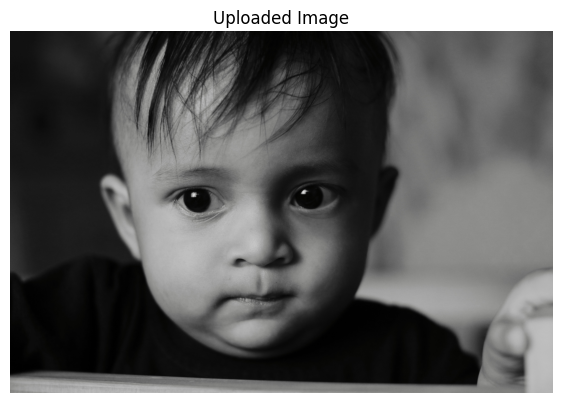

Image Shape: (4000, 6000, 3)
Image Dimension: 3


In [3]:
from google.colab import files
import cv2
import numpy as np
import matplotlib.pyplot as plt

#upload a black-and-white photograph
uploaded = files.upload()

#Get the Uploaded image filename
image_path = next(iter(uploaded))

#read the image using OpenCV
image = cv2.imread(image_path)

#Convert BGR format to RGB format
image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.figure(figsize=(7,5))
plt.imshow(image_rgb)
plt.title("Uploaded Image")
plt.axis("off")
plt.show()

print("Image Shape:", image.shape)
print("Image Dimension:", image.shape[2])

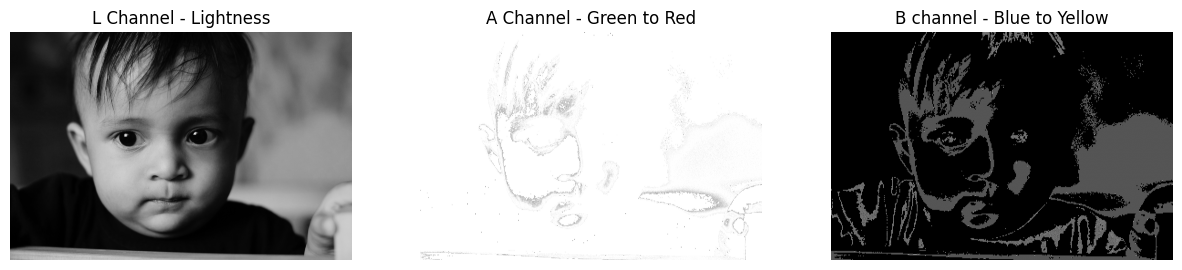

In [4]:
#Convert RGB image into LAB color Space

lab_image = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2LAB)

#Extract individual LAB channels
L_channel = lab_image[:, :, 0]
A_channel = lab_image[:, :, 1]
B_channel = lab_image[:, :, 2]

#Display the LAB channels
plt.figure(figsize = (15,5))

plt.subplot(1, 3, 1)
plt.imshow(L_channel, cmap='gray')
plt.title("L Channel - Lightness")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(A_channel, cmap='gray')
plt.title("A Channel - Green to Red")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(B_channel, cmap='gray')
plt.title("B channel - Blue to Yellow")
plt.axis('off')

plt.show()

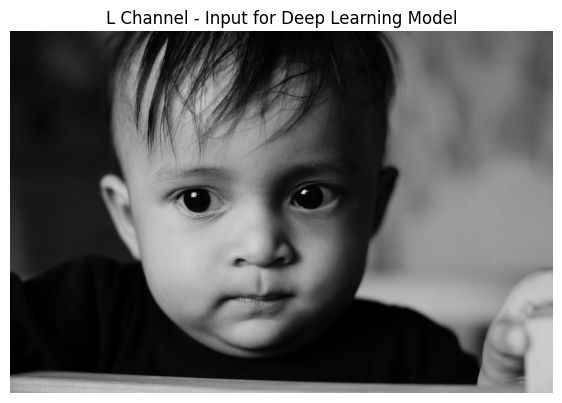

Input Shape: (4000, 6000)


In [5]:
#Extract brightness information from the image

gray_image = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)

#covert grayscale image to RGB
gray_rgb = cv2.cvtColor(gray_image, cv2.COLOR_GRAY2RGB)

#Convert RGB values from 0-255 to float32 values 0-1
gray_rgb_float = gray_rgb.astype(np.float32) / 255.0

#Convert grayscale RGB image to LAB
gray_lab = cv2.cvtColor(gray_rgb_float, cv2.COLOR_RGB2LAB)

#Extract L channel
input_L = gray_lab[:, :, 0]

#Display the model input
plt.figure(figsize=(7,5))
plt.imshow(input_L, cmap='gray')
plt.title("L Channel - Input for Deep Learning Model")
plt.axis("off")
plt.show()

print("Input Shape:", input_L.shape)

In [6]:

#Define model file paths
prototxt_path ="models/colorization_deploy_v2.prototxt"
model_path = "models/colorization_release_v2.caffemodel"
points_path = "models/pts_in_hull.npy"

#Check whether all required files exists
for path in [prototxt_path, model_path, points_path]:
  if not os.path.exists(path):
    raise FileNotFoundError(f"Required model file not found : {path}")

#Load the pretrained CNN model
net = cv2.dnn.readNetFromCaffe(prototxt_path, model_path)

print("Pretrained CNN model Loaded Successfully")

Pretrained CNN model Loaded Successfully


In [7]:
#Load the 313 color cluster points
pts = np.load(points_path)

#Reshape the points into the format expected by the network
pts = pts.transpose().reshape(2, 313, 1, 1)

#Add color cluster information to the model
net.getLayer(net.getLayerId("class8_ab")).blobs = [pts.astype("float32")]

#Configure the color rebalancing layer
net.getLayer(net.getLayerId('conv8_313_rh')).blobs= [np.full((1, 313), 2.606, dtype="float32")]

print("Color cluster point configured Successfully")

Color cluster point configured Successfully


In [8]:
# Resize the L channel to the model's expected input size
input_width = 224
input_height = 224

# FIX: use input_L (float, range 0-100) from the earlier step, not the uint8 L_channel (0-255)
L_resized = cv2.resize(input_L, (input_width, input_height))

# Center the L channel around zero (mean subtraction)
L_resized = L_resized - 50

# Convert the image into a neural network input blob
blob = cv2.dnn.blobFromImage(L_resized)

# Give the input to CNN
net.setInput(blob)

# Predict color information
ab_output = net.forward("class8_ab")

print("CNN Prediction Completed")
print("Predicted output shape:", ab_output.shape)

CNN Prediction Completed
Predicted output shape: (1, 2, 56, 56)


In [9]:
# Convert CNN output into the expected channel format
ab_output = ab_output[0].transpose((1, 2, 0))

# Resize predicted color channels to original image dimensions
ab_resized = cv2.resize(ab_output, (image.shape[1], image.shape[0]))

# FIX: combine the original-resolution L (0-100 scale) with predicted A and B channels
colorized_lab = np.concatenate((input_L[:, :, np.newaxis], ab_resized), axis=2)

print('LAB image reconstructed successfully!')
print("Reconstructed Image Shape:", colorized_lab.shape)

LAB image reconstructed successfully!
Reconstructed Image Shape: (4000, 6000, 3)


In [10]:
#Convert the reconstructed LAB Image into RGB
colorized_image = cv2.cvtColor(colorized_lab.astype(np.float32), cv2.COLOR_LAB2RGB)

#Keep pixel values within alid display range
colorized_image = np.clip(colorized_image, 0, 1)

print("Image Colorized completed Successfully")

Image Colorized completed Successfully


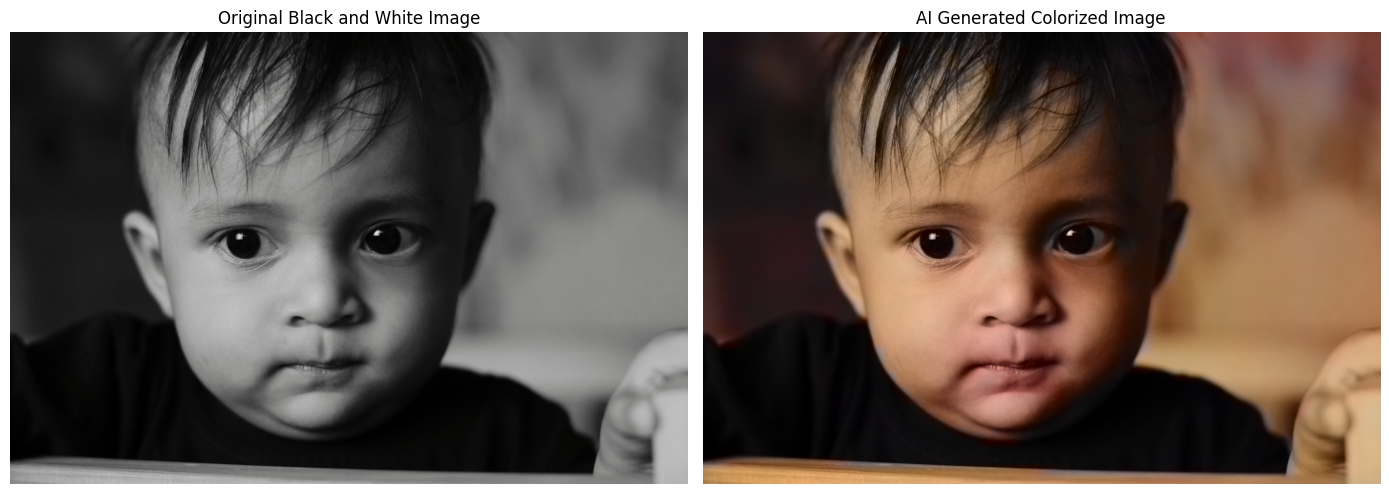

In [11]:
plt.figure(figsize=(14, 6))

#Display Original Image
plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Black and White Image")
plt.axis("off")

#Display colorized Image
plt.subplot(1,2,2)
plt.imshow(colorized_image)
plt.title("AI Generated Colorized Image")
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
#Convert RGB image into BGR fromat for OpenCV
output_bgr = cv2.cvtColor((colorized_image * 255).astype(np.uint8), cv2.COLOR_RGB2BGR)

#Save the output image
output_path = "colorized_output.jpg"

cv2.imwrite(output_path, output_bgr)
print('Colorized image svaed Successfully')

Colorized image svaed Successfully


In [13]:
files.download(output_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>